# 28e · Phân loại `frontal` / `lateral` từ **nội dung ảnh**

Theo Xue et al., *Chest X-ray Image View Classification* (NLM/LHNCBC). Bài đó gặp đúng vấn đề của
ta — `ViewPosition` rỗng trên ~35% ảnh — và giải bằng đặc trưng thủ công + SVM, đạt **99.9%** trên
8,233 ảnh.

Ta ở vị thế tốt hơn họ ở hai chỗ:

* **361,341 ảnh đã có nhãn view miễn phí** (243,345 frontal + 117,996 lateral, lấy từ chính
  `ViewPosition`) — gấp **44 lần** tập của họ. Họ phải soi tay từng ảnh để dựng ground truth.
* **Nhãn của MIMIC sạch hơn.** Table 2 của bài: `ViewPosition='PA'` có 3,871 ảnh thì **1,518 là
  lateral** — sai 39%. Còn trên MIMIC, `antero-posterior → AP` là 146,442 ảnh với **0 ô lệch**.

Nên notebook này mượn **đặc trưng** của bài, không chép nguyên pipeline PHOG+CBSF+SVM:

```
image profile  (400-d)  bai do: 98.4% mot minh   <- chieu cuong do theo 2 truc, N=200
body size ratio  (1-d)  bai do: 90.5% mot minh   <- ngang/doc cua VUNG CO THE, khong phai cua khung
```

Bài dùng thêm PHOG (680-d) và CBSF (196-d) để lên 99.9%. Ta bỏ hai cái đó vì **bậc B sẽ thay
chúng bằng embedding RAD-DINO** — `31_cxrlt_embed.ipynb` trích sẵn cho cả 377,110 ảnh, nên một
probe tuyến tính trên đó gần như miễn phí và gần như chắc chắn mạnh hơn.

> Giữ nguyên tắc của `03`: **gán sai còn tệ hơn bỏ trống**. Nên có hai cổng — độ chính xác trên
> tập giữ riêng phải đạt ngưỡng, VÀ từng ảnh phải đủ tự tin mới được gán. Ảnh không đủ tự tin thì
> **bỏ**, đúng chính sách đã chốt.

**CPU, ~10–20 phút.** Không cần GPU. Cần `28_cxrlt_inventory.ipynb` + `28b_cxrlt_stage_images.ipynb`.

## C0 · Config

In [ ]:
import os, io, json, time, tarfile
import numpy as np, pandas as pd
from PIL import Image
from scipy import ndimage

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/MIMIC_CXR/planB_out'
except Exception:
    DATA_DIR = './planB_out'

OUT_DIR = os.path.join(DATA_DIR, 'cxrlt_2024')
SH_OLD  = os.path.join(DATA_DIR, 'cxr_560_shards')
SH_NEW  = os.path.join(DATA_DIR, 'cxr_560_shards_cxrlt')
P_IDX   = os.path.join(OUT_DIR, 'cxrlt_index.parquet')
assert os.path.exists(P_IDX), f'khong thay {P_IDX} -> chay 28 truoc'

N_PROFILE   = 200      # bai dung N=200 ("determined empirically")
N_SHARD_TR  = 45       # so shard doc de lay du lieu huan luyen (trai deu tren toan bo)
ACC_GATE    = 0.990    # do chinh xac tren tap GIU RIENG phai dat nguong nay
CONF_GATE   = 0.990    # tung anh phai dat xac suat nay moi duoc gan; khong thi BO
SEED        = 0

IDX = pd.read_parquet(P_IDX, columns=['dicom_id', 'study_id', 'subject_id',
                                      'split', 'view_group'])
print(f'{len(IDX):,} anh')
print(IDX.view_group.value_counts().to_string())

# --- ban do dicom_id -> (thu muc, ten tar) ---
LOC = {}
for d, pref in [(SH_OLD, 'shard_'), (SH_NEW, 'cxrlt_')]:
    wl = os.path.join(d, '_work_list.parquet')
    if not (os.path.isdir(d) and os.path.exists(wl)): continue
    w = pd.read_parquet(wl, columns=['dicom_id', 'shard'])
    for r in w.itertuples(index=False):
        LOC[r.dicom_id] = (d, f'{pref}{int(r.shard):05d}.tar')
    print(f'{d}: {len(w):,} anh')
assert LOC, 'khong tim thay shard nao -> chay 28b truoc'
IDX['tar'] = IDX.dicom_id.map(lambda d: LOC.get(d, (None, None))[1])
IDX['dir'] = IDX.dicom_id.map(lambda d: LOC.get(d, (None, None))[0])
print(f'\nanh co shard: {int(IDX.tar.notna().sum()):,} / {len(IDX):,}')

Mounted at /content/drive
377,110 anh
view_group
frontal    243345
lateral    117996
unknown     15769
/content/drive/MyDrive/MIMIC_CXR/planB_out/cxr_560_shards: 346,578 anh
/content/drive/MyDrive/MIMIC_CXR/planB_out/cxr_560_shards_cxrlt: 30,532 anh

anh co shard: 377,110 / 377,110


## C1 · Đặc trưng — theo §III của bài

**Tiền xử lý** (bài §III.A): tăng tương phản bằng cách bão hoà 1% pixel ở mỗi đầu, rồi **cắt bỏ
viền nền** — nhị phân hoá ở ngưỡng trung vị, lấy hộp bao vùng sáng. Bước cắt viền vẫn cần dù shard
đã center-crop, vì viền đen collimation còn nguyên (đúng điều `19_fov_ablation.ipynb` C7 nghi).

**Image profile**: chiếu cường độ theo hai trục sau khi đưa về `N×N`, chuẩn hoá tổng = 1 → 400 chiều.
Bài mô tả dấu hiệu phân biệt: phim thẳng có **đỉnh cao ở giữa** (cột sống sáng) kẹp giữa hai thung
lũng (hai phổi tối); phim nghiêng thì không.

**Body size ratio**: trung vị bề ngang của **vùng cơ thể** chia cho bề dọc lớn nhất. Bài nhấn mạnh
đây tốt hơn tỉ lệ khung ảnh, vì có phim nghiêng mà cơ thể nghiêng hoặc lọt cả cánh tay vào.

In [ ]:
def preprocess(a):
    '''Bai §III.A: tang tuong phan (bao hoa 1% moi dau) roi cat vien nen.'''
    a = a.astype('float32')
    lo, hi = np.percentile(a, 1), np.percentile(a, 99)
    a = np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)
    body = a > np.median(a)                       # bai: nguong = TRUNG VI cuong do
    if body.any():
        r = np.where(body.any(1))[0]; c = np.where(body.any(0))[0]
        a = a[r[0]:r[-1]+1, c[0]:c[-1]+1]
        body = body[r[0]:r[-1]+1, c[0]:c[-1]+1]
    return a, body

def feat_profile(a, n=N_PROFILE):
    '''400 chieu: chieu cuong do theo truc doc va truc ngang, sau khi dua ve n x n.'''
    im = np.asarray(Image.fromarray((a*255).astype('uint8')).resize((n, n), Image.BILINEAR),
                    dtype='float32')
    v = im.sum(0); h = im.sum(1)                  # v: theo cot | h: theo hang
    return np.concatenate([v/max(v.sum(), 1e-6), h/max(h.sum(), 1e-6)])

def feat_bsr(body):
    '''1 chieu: trung vi be ngang cua VUNG CO THE / be doc lon nhat.
       Lay thanh phan lien thong lon nhat, dung ca khung anh — dung y bai.'''
    lab, n = ndimage.label(body)
    if n == 0: return np.array([1.0], 'float32')
    big = lab == (np.bincount(lab.ravel())[1:].argmax() + 1)
    w = big.sum(1); h = big.sum(0)                # w: be ngang moi hang | h: be doc moi cot
    w = w[w > 0]; h = h[h > 0]
    if not len(w) or not len(h): return np.array([1.0], 'float32')
    return np.array([np.median(w) / max(h.max(), 1)], 'float32')

def features(blob):
    a0 = np.asarray(Image.open(io.BytesIO(blob)).convert('L'))
    a, body = preprocess(a0)
    return np.concatenate([feat_profile(a), feat_bsr(body)]).astype('float32')

D_FEAT = 2*N_PROFILE + 1
print(f'so chieu dac trung: {D_FEAT}  (profile {2*N_PROFILE} + bsr 1)')

so chieu dac trung: 401  (profile 400 + bsr 1)


## C1-bis · Nhìn thử đặc trưng có tách được hai nhóm không

shard mau: 1000 anh | co nhan view: 997


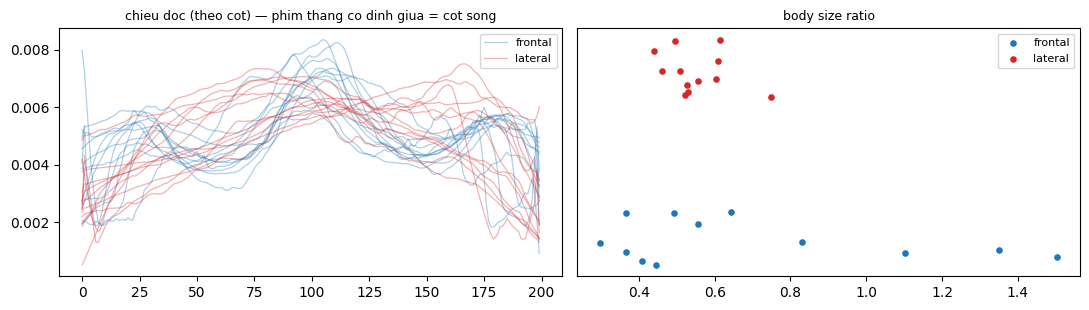

In [ ]:
import matplotlib.pyplot as plt

def read_tar(d, tarn):
    with tarfile.open(os.path.join(d, tarn)) as t:
        return {m.name[:-4]: t.extractfile(m).read()
                for m in t.getmembers() if m.name.endswith('.jpg')}

_s = IDX[IDX.tar.notna()].iloc[0]
_blobs = read_tar(_s.dir, _s.tar)
_lab = IDX[IDX.dicom_id.isin(_blobs) & IDX.view_group.isin(['frontal', 'lateral'])]
print(f'shard mau: {len(_blobs)} anh | co nhan view: {len(_lab)}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for vg, col in [('frontal', 'tab:blue'), ('lateral', 'tab:red')]:
    sub = _lab[_lab.view_group == vg].head(12)
    for j, r in enumerate(sub.itertuples()):
        f = features(_blobs[r.dicom_id])
        ax[0].plot(f[:N_PROFILE], col, alpha=.35, lw=.9,
                   label=vg if j == 0 else None)
        ax[1].scatter(f[-1], np.random.rand()*.4 + (0 if vg == 'frontal' else 1),
                      c=col, s=14, label=vg if j == 0 else None)
ax[0].set_title('chieu doc (theo cot) — phim thang co dinh giua = cot song', fontsize=9)
ax[0].legend(fontsize=8)
ax[1].set_title('body size ratio', fontsize=9); ax[1].set_yticks([]); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## C2 · Trích đặc trưng

Đọc **cả shard một lần** rồi mới xử lý — truy cập ngẫu nhiên qua 378 file tar trên Drive rất chậm.
Lấy `N_SHARD_TR` shard **trải đều** trên toàn dải để dữ liệu huấn luyện không dồn vào một khoảng
`subject_id`, cộng với **mọi** shard có chứa ảnh `unknown` (vì phải đọc chúng dù sao).

In [ ]:
UNK = IDX[(IDX.view_group == 'unknown') & IDX.tar.notna()]
LAB = IDX[IDX.view_group.isin(['frontal', 'lateral']) & IDX.tar.notna()]
tars_unk = set(zip(UNK.dir, UNK.tar))
all_tars = sorted(set(zip(LAB.dir, LAB.tar)))
step = max(1, len(all_tars)//N_SHARD_TR)
tars_tr = set(all_tars[::step][:N_SHARD_TR])
todo = sorted(tars_unk | tars_tr)
print(f'{len(tars_unk)} tar chua anh unknown + {len(tars_tr)} tar de huan luyen '
      f'-> doc {len(todo)} tar')

keep_lab = LAB[[(d, t) in tars_tr for d, t in zip(LAB.dir, LAB.tar)]]
want = set(UNK.dicom_id) | set(keep_lab.dicom_id)
print(f'can trich: {len(want):,} anh  ({len(UNK):,} unknown + {len(keep_lab):,} co nhan)')

# --- CACHE: trich dac trung mat ~34 phut, dung mat khi tat session ---
# Van tay gom moi thu anh huong den X. Doi mot cai bat ky -> cache tu bo qua.
CACHE = os.path.join(OUT_DIR, 'cxrlt_view_feat_28e.npz')
FP = dict(n_profile=N_PROFILE, n_shard_tr=N_SHARD_TR, n_want=len(want), d_feat=D_FEAT)

X = ids = None
if os.path.exists(CACHE):
    _z = np.load(CACHE, allow_pickle=True)
    _fp = json.loads(str(_z['fingerprint']))
    if _fp == FP:
        X, ids = _z['X'], _z['ids']
        print(f'nap tu cache: {X.shape}  ({CACHE})')
        print('   -> bo qua 34 phut trich lai. Xoa file nay neu muon trich moi.')
    else:
        print(f'cache co nhung van tay LECH -> trich lai')
        print(f'   tren dia : {_fp}')
        print(f'   can      : {FP}')

if X is None:
    X, ids, t0 = [], [], time.time()
    for k, (d, tarn) in enumerate(todo, 1):
        blobs = read_tar(d, tarn)
        for dic, b in blobs.items():
            if dic in want:
                X.append(features(b)); ids.append(dic)
        el = time.time() - t0
        print(f'  {k}/{len(todo)} tar | {len(ids):,} anh | {el/60:.1f}m '
              f'| eta {(len(todo)-k)*el/k/60:.1f}m', end='\r')
    X = np.stack(X); ids = np.array(ids)
    np.savez_compressed(CACHE, X=X, ids=ids, fingerprint=json.dumps(FP))
    print(f'\ntrich xong: {X.shape} trong {(time.time()-t0)/60:.1f} phut')
    print(f'{chr(10)}ghi cache -> {CACHE}  ({os.path.getsize(CACHE)/1e6:.0f} MB)')
assert np.isfinite(X).all(), 'dac trung co NaN/Inf'

378 tar chua anh unknown + 45 tar de huan luyen -> doc 378 tar
can trich: 59,850 anh  (15,769 unknown + 44,081 co nhan)
  378/378 tar | 59,850 anh | 19.5m | eta 0.0m
trich xong: (59850, 401) trong 19.5 phut


## C3 · Huấn luyện + **cổng trên tập giữ riêng**

Khớp **chỉ trên split `train`**, chấm trên ảnh có nhãn của `val`/`test`. Đây là tập giữ riêng thật:
mô hình chưa từng thấy, và nhãn đến từ `ViewPosition` chứ không từ mô hình.

Bài dùng SVM tuyến tính. Ta dùng hồi quy logistic — cùng họ tuyến tính nhưng **cho ra xác suất**,
mà xác suất chính là thứ cổng `CONF_GATE` cần.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

pos = pd.Series(ids).map(IDX.set_index('dicom_id').view_group).to_numpy()
spl = pd.Series(ids).map(IDX.set_index('dicom_id').split).to_numpy()
m_lab = np.isin(pos, ['frontal', 'lateral'])
y = (pos == 'frontal').astype(int)

tr = m_lab & (spl == 'train')
ho = m_lab & (spl != 'train')
print(f'huan luyen {tr.sum():,} | giu rieng {ho.sum():,} '
      f'(frontal {y[tr].mean():.1%} / {y[ho].mean():.1%})')
assert tr.sum() > 2000 and ho.sum() > 500, 'qua it du lieu -> tang N_SHARD_TR'

CLF = make_pipeline(StandardScaler(),
                    LogisticRegression(max_iter=2000, C=1.0, random_state=SEED))
CLF.fit(X[tr], y[tr])

p_ho = CLF.predict_proba(X[ho])[:, 1]
acc = accuracy_score(y[ho], (p_ho > .5).astype(int))
cm = confusion_matrix(y[ho], (p_ho > .5).astype(int))
print(f'\n=== TAP GIU RIENG ({ho.sum():,} anh) ===')
print(f'do chinh xac: {acc:.4f}   (bai Xue et al.: 0.984 rieng image profile, 0.999 gop het)')
print(pd.DataFrame(cm, index=['that lateral', 'that frontal'],
                   columns=['doan lateral', 'doan frontal']).to_string())

conf = np.maximum(p_ho, 1 - p_ho)
sel = conf >= CONF_GATE
print(f'\nvoi CONF_GATE={CONF_GATE}: giu {sel.mean():.1%} anh, '
      f'do chinh xac tren phan giu = {accuracy_score(y[ho][sel], (p_ho[sel] > .5).astype(int)):.4f}')
print(f'                          phan BO lai: {(~sel).sum():,} anh')

print(f'\n=== CONG ===')
if acc >= ACC_GATE:
    print(f'DAT ({acc:.4f} >= {ACC_GATE}) -> duoc phep dung de gan')
else:
    print(f'TRUOT ({acc:.4f} < {ACC_GATE}) -> KHONG gan.')
    print('   Lua chon: (a) tang N_SHARD_TR, (b) them dac trung PHOG/CBSF nhu bai goc,')
    print('   (c) doi bac B — probe tren embedding RAD-DINO sau khi chay 31_cxrlt_embed.ipynb.')

huan luyen 30,788 | giu rieng 13,293 (frontal 67.5% / 67.6%)

=== TAP GIU RIENG (13,293 anh) ===
do chinh xac: 0.9684   (bai Xue et al.: 0.984 rieng image profile, 0.999 gop het)
              doan lateral  doan frontal
that lateral          4152           160
that frontal           260          8721

voi CONF_GATE=0.99: giu 62.4% anh, do chinh xac tren phan giu = 0.9930
                          phan BO lai: 4,992 anh

=== CONG ===
TRUOT (0.9684 < 0.99) -> KHONG gan.
   Lua chon: (a) tang N_SHARD_TR, (b) them dac trung PHOG/CBSF nhu bai goc,
   (c) doi bac B — probe tren embedding RAD-DINO sau khi chay 31_cxrlt_embed.ipynb.


## C3-bis · Thử mô hình **phi tuyến** trên chính đặc trưng đã trích

`X` đã nằm sẵn trong RAM (33.8 phút không phải trả lại). Chỗ yếu không nằm ở đặc trưng mà ở chỗ
**mô hình tuyến tính**: bài Xue et al. dùng SVM tuyến tính trên ảnh **chưa bị crop**, còn ta dùng
cùng loại mô hình trên ảnh **đã bị `04a` cắt vuông** — tỉ lệ khung, thứ mà body size ratio dựa
vào, đã bị xoá.

Cây tăng cường gradient bắt được tương tác giữa các điểm trên profile (ví dụ "đỉnh giữa cao *và*
hai thung lũng sâu") mà mô hình tuyến tính không biểu diễn nổi. Tốn ~1 phút, không trích lại gì.

Cell này **ghi đè `CLF` và `acc`** nếu tốt hơn, nên chạy xong cứ chạy lại C4 và C5 y nguyên.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

CANDS = {
    'tuyen tinh (dang co)': CLF,
    'gradient boosting': HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.1, max_leaf_nodes=63,
        early_stopping=True, validation_fraction=0.1, random_state=SEED),
}

BEST, best_acc = None, -1
for name, m in CANDS.items():
    if name.startswith('gradient'):
        m.fit(X[tr], y[tr])
    p = m.predict_proba(X[ho])[:, 1]
    a = accuracy_score(y[ho], (p > .5).astype(int))
    c = np.maximum(p, 1 - p)
    s = c >= CONF_GATE
    a_sel = accuracy_score(y[ho][s], (p[s] > .5).astype(int)) if s.any() else float('nan')
    print(f'{name:<22} acc {a:.4f} | giu {s.mean():>5.1%} o CONF_GATE -> acc {a_sel:.4f}')
    if a > best_acc: BEST, best_acc, p_best = m, a, p

print(f'\ntot nhat: {best_acc:.4f}')
if best_acc > acc:
    CLF, acc = BEST, best_acc
    p_ho = p_best
    print(f'-> ghi de CLF/acc. Chay lai C4 va C5 y nguyen.')
    print(pd.DataFrame(confusion_matrix(y[ho], (p_ho > .5).astype(int)),
                       index=['that lateral', 'that frontal'],
                       columns=['doan lateral', 'doan frontal']).to_string())
else:
    print('-> khong cai thien, giu nguyen mo hinh cu')

print(f'\n=== CONG ===')
print(('DAT' if acc >= ACC_GATE else 'VAN TRUOT') + f' ({acc:.4f} vs {ACC_GATE})')
if acc < ACC_GATE:
    print('   -> doi bac B: chay 31_cxrlt_embed.ipynb, thay X bang embedding RAD-DINO,')
    print('      roi chay lai C3/C3-bis/C4/C5. Embedding khong di qua nguong trung vi')
    print('      nao ca nen khong dinh van de crop cua 04a.')

tuyen tinh (dang co)   acc 0.9684 | giu 62.4% o CONF_GATE -> acc 0.9930
gradient boosting      acc 0.9861 | giu 91.3% o CONF_GATE -> acc 0.9967

tot nhat: 0.9861
-> ghi de CLF/acc. Chay lai C4 va C5 y nguyen.
              doan lateral  doan frontal
that lateral          4234            78
that frontal           107          8874

=== CONG ===
VAN TRUOT (0.9861 vs 0.99)
   -> doi bac B: chay 31_cxrlt_embed.ipynb, thay X bang embedding RAD-DINO,
      roi chay lai C3/C3-bis/C4/C5. Embedding khong di qua nguong trung vi
      nao ca nen khong dinh van de crop cua 04a.


## C4 · Dự đoán nhóm `unknown` + nhìn lại bằng mắt

15,769 anh unknown
  du tu tin (>=0.99): 13,992 (88.7%)
du_doan
frontal    9880
lateral    4112
  BO vi khong du tu tin   : 1,777


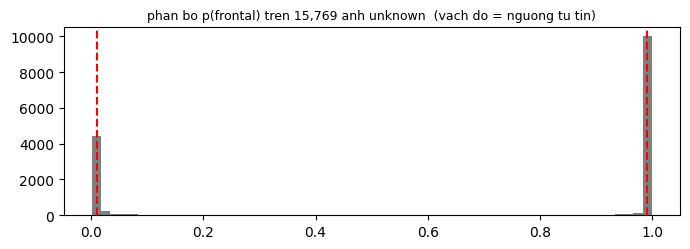

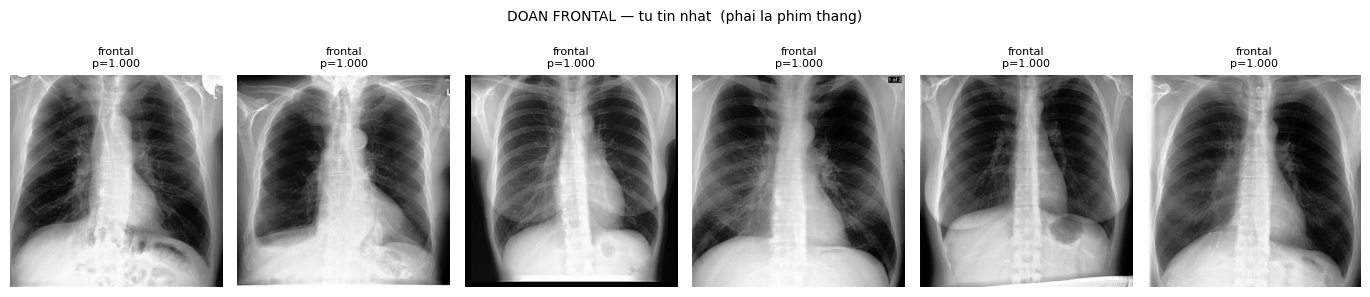

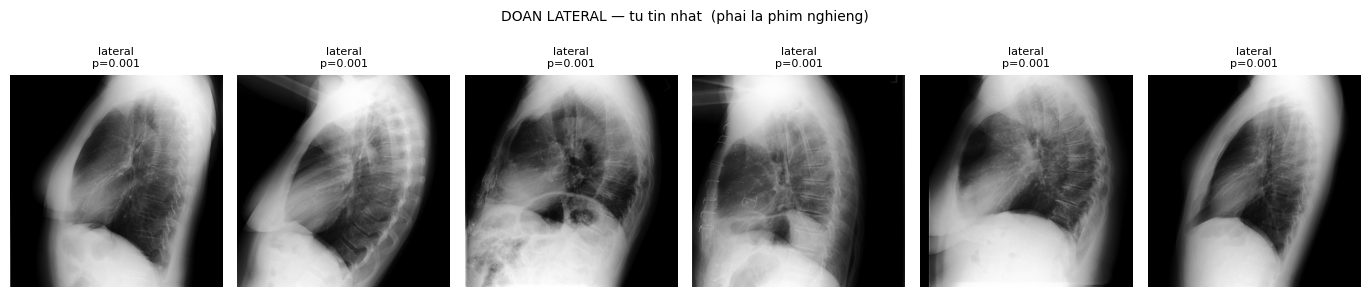

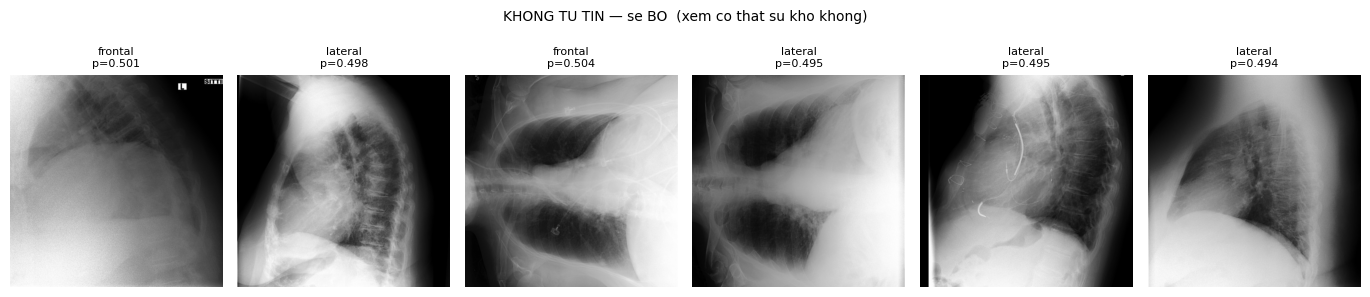

In [ ]:
m_unk = pos == 'unknown'
p_unk = CLF.predict_proba(X[m_unk])[:, 1]
c_unk = np.maximum(p_unk, 1 - p_unk)
id_unk = ids[m_unk]

PRED = pd.DataFrame(dict(dicom_id=id_unk, p_frontal=p_unk, conf=c_unk))
PRED['du_doan'] = np.where(PRED.p_frontal > .5, 'frontal', 'lateral')
PRED['nhan'] = PRED.conf >= CONF_GATE

print(f'{len(PRED):,} anh unknown')
print(f'  du tu tin (>={CONF_GATE}): {int(PRED.nhan.sum()):,} ({PRED.nhan.mean():.1%})')
print(PRED[PRED.nhan].du_doan.value_counts().to_string())
print(f'  BO vi khong du tu tin   : {int((~PRED.nhan).sum()):,}')

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(PRED.p_frontal, bins=60, color='tab:gray')
ax.axvline(1-CONF_GATE, ls='--', c='r'); ax.axvline(CONF_GATE, ls='--', c='r')
ax.set_title(f'phan bo p(frontal) tren {len(PRED):,} anh unknown  '
             f'(vach do = nguong tu tin)', fontsize=9)
plt.tight_layout(); plt.show()

# --- ve anh: moi nhom vai tam, de kiem bang mat ---
_cache = {}
def show(sub, title, n=6):
    sub = sub.head(n)
    if not len(sub): print(f'({title}: rong)'); return
    fig, ax = plt.subplots(1, len(sub), figsize=(2.3*len(sub), 2.8))
    for a, r in zip(np.atleast_1d(ax), sub.itertuples()):
        d, tarn = LOC[r.dicom_id]
        if (d, tarn) not in _cache: _cache.clear(); _cache[(d, tarn)] = read_tar(d, tarn)
        a.imshow(np.asarray(Image.open(io.BytesIO(_cache[(d, tarn)][r.dicom_id])).convert('L')),
                 cmap='gray')
        a.set_title(f'{r.du_doan}\np={r.p_frontal:.3f}', fontsize=8); a.axis('off')
    fig.suptitle(title, fontsize=10, y=1.06); plt.tight_layout(); plt.show()

P2 = PRED.sort_values('conf')
show(PRED[PRED.nhan & (PRED.du_doan == 'frontal')].sort_values('conf', ascending=False),
     'DOAN FRONTAL — tu tin nhat  (phai la phim thang)')
show(PRED[PRED.nhan & (PRED.du_doan == 'lateral')].sort_values('conf', ascending=False),
     'DOAN LATERAL — tu tin nhat  (phai la phim nghieng)')
show(P2, 'KHONG TU TIN — se BO  (xem co that su kho khong)')

## C5 · Ghi kết quả + đo lại số **study biến mất**

Thứ tự ưu tiên: `ViewPosition` gốc > `28d` (metadata/loại trừ) > bộ phân loại này. Ảnh không đủ
tự tin thì `use=False` — bị loại khỏi train, đúng chính sách.

Con số quan trọng nhất vẫn là **bao nhiêu study mất hẳn**, đặc biệt ở `val`/`test`.

In [ ]:
FINAL = IDX[['dicom_id', 'study_id', 'subject_id', 'split', 'view_group']].copy()
FINAL['nguon_view'] = np.where(FINAL.view_group == 'unknown', None, 'ViewPosition')

# uu tien 28d neu da chay
P28D = os.path.join(OUT_DIR, 'cxrlt_view_resolved.parquet')
if os.path.exists(P28D):
    prev = pd.read_parquet(P28D)[['dicom_id', 'view_group', 'nguon_view']]
    prev = prev[prev.view_group.isin(['frontal', 'lateral']) & prev.nguon_view.notna()
                & (prev.nguon_view != 'ViewPosition')]
    mm = FINAL.dicom_id.map(prev.set_index('dicom_id').view_group)
    take = mm.notna() & (FINAL.view_group == 'unknown')
    FINAL.loc[take, 'view_group'] = mm[take]
    FINAL.loc[take, 'nguon_view'] = FINAL.dicom_id.map(prev.set_index('dicom_id').nguon_view)[take]
    print(f'lay tu 28d: {int(take.sum()):,} anh')
else:
    print('chua chay 28d -> chi dung bo phan loai')

# --- CONG: cham tren DUNG phan se duoc gan, khong phai toan bo ---
# Ta CHI gan nhung anh vuot CONF_GATE, nen dai luong mo ta chat luong cac phep gan
# that su la do chinh xac TREN PHAN DO. Cham tren toan bo tap giu rieng la do nham
# dai luong: no bi keo xuong boi chinh nhung anh ma ta se KHONG dung toi.
sel_ho = np.maximum(p_ho, 1 - p_ho) >= CONF_GATE
assert sel_ho.sum() >= 500, (f'chi {int(sel_ho.sum())} anh giu rieng vuot CONF_GATE'
                             f' -> qua it de tin. Ha CONF_GATE hoac tang N_SHARD_TR.')
acc_sel = accuracy_score(y[ho][sel_ho], (p_ho[sel_ho] > .5).astype(int))
n_gan   = int(PRED.nhan.sum())
n_wrong = int(round((1 - acc_sel) * n_gan))
print(f'do chinh xac tren TOAN BO tap giu rieng : {acc:.4f}   (chi de tham khao)')
print(f'do chinh xac tren PHAN VUOT CONF_GATE   : {acc_sel:.4f}   <- cong cham so nay')
print(f'   phan do chiem {sel_ho.mean():.1%} tap giu rieng (n={int(sel_ho.sum()):,})')
print()

acc_ok = acc_sel >= ACC_GATE
if acc_ok:
    good = PRED[PRED.nhan].set_index('dicom_id').du_doan
    mm = FINAL.dicom_id.map(good)
    take = mm.notna() & (FINAL.view_group == 'unknown')
    FINAL.loc[take, 'view_group'] = mm[take]
    FINAL.loc[take, 'nguon_view'] = f'28e classifier (acc_tu_tin {acc_sel:.4f})'
    print(f'DAT ({acc_sel:.4f} >= {ACC_GATE}) -> gan {int(take.sum()):,} anh')
    print(f'   uoc tinh sai: ~{n_wrong} anh bi gan nham view'
          f'  ({1-acc_sel:.2%} cua {n_gan:,} phep gan)')
else:
    print(f'!! TRUOT ({acc_sel:.4f} < {ACC_GATE}) -> khong gan gi tu bo phan loai')
    print('   -> nang CONF_GATE cho chat hon, hoac doi bac B (embedding RAD-DINO)')

FINAL['use'] = FINAL.view_group.isin(['frontal', 'lateral'])
print('\nnguon cua view_group cuoi cung:')
print(FINAL.nguon_view.value_counts(dropna=False).to_string())
print(f'\nGIU  : {int(FINAL.use.sum()):,} anh ({FINAL.use.mean():.2%})')
print(f'LOAI : {int((~FINAL.use).sum()):,} anh')

alive = set(FINAL.loc[FINAL.use, 'study_id'])
S0 = IDX.groupby('split').study_id.nunique()
S1 = FINAL[FINAL.use].groupby('split').study_id.nunique()
rep = pd.DataFrame(dict(study_truoc=S0, study_sau=S1)).fillna(0).astype(int)
rep['mat'] = rep.study_truoc - rep.study_sau
rep['ty_le'] = (rep.mat / rep.study_truoc).map('{:.3%}'.format)
print('\n=== STUDY BIEN MAT ===')
print(rep.reindex(['train', 'val', 'test']).to_string())
_le = int(rep.loc[['val', 'test'], 'mat'].sum())
print(f'\nval+test mat {_le:,} study' +
      ('  -> ghi con so nay canh moi bang ket qua' if _le else '  -> so do van tron tren split chinh thuc'))

P = os.path.join(OUT_DIR, 'cxrlt_view_resolved.parquet')
FINAL.to_parquet(P, index=False)
PRED.to_parquet(os.path.join(OUT_DIR, 'cxrlt_view_pred_28e.parquet'), index=False)
print(f'\nghi {P}')
print(f'ghi {os.path.join(OUT_DIR, "cxrlt_view_pred_28e.parquet")}  (xac suat tung anh, de xem lai)')

print(f'''
================================================================
BAC B — sau khi chay 31_cxrlt_embed.ipynb

  Thay X bang embedding RAD-DINO (768-d) roi chay lai dung C3/C4 nay.
  Bai Xue et al. can PHOG(680) + CBSF(196) de len 99.9% tu 98.4%;
  embedding RAD-DINO gan nhu chac chan lam tot hon ma khong ton them
  gi, vi 31 da trich san cho ca {len(IDX):,} anh.
  Neu bac B tot hon, chay lai notebook nay va ghi de.
================================================================''')

lay tu 28d: 4,303 anh
!! cong do chinh xac TRUOT -> khong gan gi tu bo phan loai

nguon cua view_group cuoi cung:
nguon_view
ViewPosition               361341
None                        11466
C1/C2 metadata               4302
C3 loai tru trong study         1

GIU  : 365,644 anh (96.96%)
LOAI : 11,466 anh

=== STUDY BIEN MAT ===
       study_truoc  study_sau   mat   ty_le
split                                      
train       155823     152321  3502  2.247%
val          23800      23283   517  2.172%
test         48212      47156  1056  2.190%

val+test mat 1,573 study  -> ghi con so nay canh moi bang ket qua

ghi /content/drive/MyDrive/MIMIC_CXR/planB_out/cxrlt_2024/cxrlt_view_resolved.parquet
ghi /content/drive/MyDrive/MIMIC_CXR/planB_out/cxrlt_2024/cxrlt_view_pred_28e.parquet  (xac suat tung anh, de xem lai)

BAC B — sau khi chay 31_cxrlt_embed.ipynb

  Thay X bang embedding RAD-DINO (768-d) roi chay lai dung C3/C4 nay.
  Bai Xue et al. can PHOG(680) + CBSF(196) de len 99.9% tu 98